In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scripts.extract_dataset as ed
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull, QhullError

In [109]:
# Read in the dataset
iclr2025v2 = pd.read_parquet("data/master.parquet")
iclr2025v2 = iclr2025v2[
    (iclr2025v2["authors"] != "Anonymous") &
    (iclr2025v2["year"] > 2020)
]

iclr2025v2.head()

,paper_idx,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels,n_authors,last_author,last_author_id,has_author_ids,decision_group,accepted,mean_score,embedding
5637,5637,2021,--GJkm7nt0,Enhancing Visual Representations for Efficient...,"We propose ENVISE, an online distillation fra...","Shashanka Venkataramanan, Bruce W McIntosh, Ab...","~Shashanka_Venkataramanan1, ~Bruce_W_McIntosh1...",Reject,"[4, 5, 5, 4]",[],unlabeled,3,Abhijit Mahalanobis,~Abhijit_Mahalanobis1,True,reject,False,4.500000,"[-0.048169, 0.060541, -0.020332, 0.1288, -0.04..."
5638,5638,2021,--gvHfE3Xf5,Meta-Learning of Structured Task Distributions...,"In recent years, meta-learning, in which a mod...","Sreejan Kumar, Ishita Dasgupta, Jonathan Cohen...","~Sreejan_Kumar1, ~Ishita_Dasgupta1, ~Jonathan_...",Accept (Poster),"[6, 6, 7, 7]","[meta-learning, human cognition, reinforcement...",meta learning,5,Thomas Griffiths,~Thomas_Griffiths1,True,accept,True,6.500000,"[0.053333, -0.003451, -0.059186, -0.092884, -0..."
5639,5639,2021,--rcOeCKRh,CROSS-SUPERVISED OBJECT DETECTION,After learning a new object category from imag...,"Zitian Chen, Zhiqiang Shen, Jiahui Yu, Erik Le...","~Zitian_Chen1, ~Zhiqiang_Shen1, ~Jiahui_Yu1, ~...",Reject,"[6, 4, 6, 6]","[object detection, weakly supervised, transfer...",object detection,4,Erik Learned-Miller,~Erik_Learned-Miller2,True,reject,False,5.500000,"[0.024876, -0.031187, 0.048518, 0.132181, 0.03..."
5640,5640,2021,-2FCwDKRREu,Learning Invariant Representations for Reinfor...,We study how representation learning can accel...,"Amy Zhang, Rowan Thomas McAllister, Roberto Ca...","~Amy_Zhang1, ~Rowan_Thomas_McAllister1, ~Rober...",Accept (Oral),"[7, 7, 9]","[rich observations, bisimulation metrics, repr...",unlabeled,5,Sergey Levine,~Sergey_Levine1,True,accept,True,7.666667,"[-0.102663, 0.114053, -0.030107, 0.016141, -0...."
5641,5641,2021,-5VpoDCExrU,Log representation as an interface for log pro...,"Log files are files that record events, messag...","Mohammad Amin Sadeghi, Shameem Parambath, Ji L...","~Mohammad_Amin_Sadeghi3, spparambath@hbku.edu....",Reject,"[7, 4, 5, 3]","[vector embedding, logs, search, causal analys...",anomaly detection,8,Sanjay Chawla,~Sanjay_Chawla2,True,reject,False,4.750000,"[-0.058153, 0.126793, -0.004362, 0.054084, -0...."


The below plot illustrates the variance explained by the found principal components, in this case where we use SBERT with embeddings the size 768.

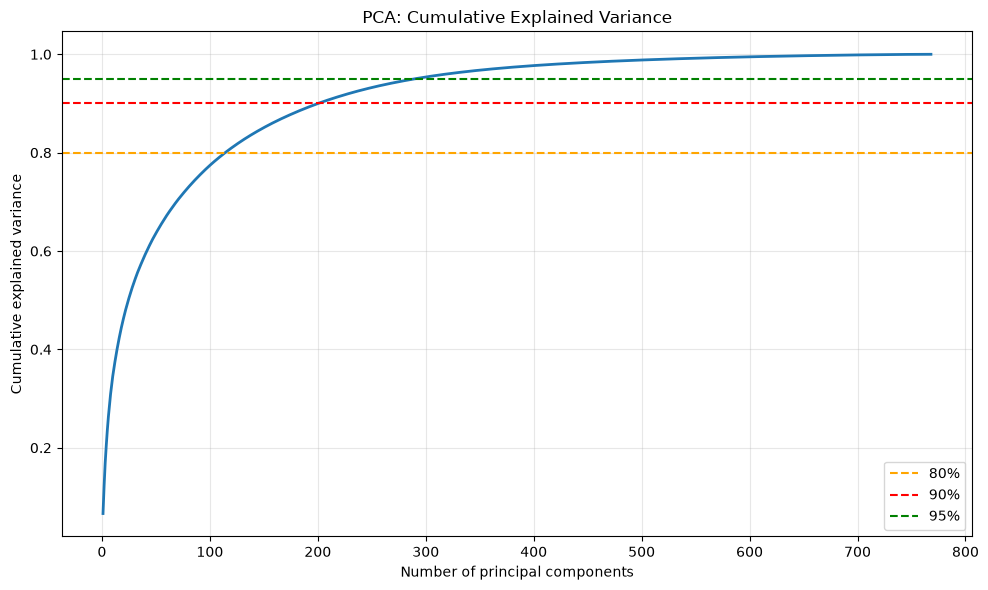

50% variance: 25 components
60% variance: 42 components
70% variance: 69 components
80% variance: 115 components
90% variance: 201 components
95% variance: 290 components


In [ ]:
embeddings = np.vstack(
    iclr2025v2["embedding"].apply(np.asarray).values
)

pca_full = PCA()
pca_full.fit(embeddings)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)

plt.axhline(0.80, linestyle="--", color="orange", label="80%")
plt.axhline(0.90, linestyle="--", color="red", label="90%")
plt.axhline(0.95, linestyle="--", color="green", label="95%")

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Number of components needed
for threshold in [0.5,0.6, 0.7, 0.80, 0.90, 0.95]:
    n = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    print(f"{threshold:.0%} variance: {n} components")


This computes the PCA for a set number of components, adding the components to the dataframe as columns.

In [ ]:
def compute_pca(
    df: pd.DataFrame,
    embedding_col: str = "embedding",
    n_components: int = 3,
    scale: bool = False,
    random_state: int = 42,
    verbose: bool = True,
):
    """

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing article embeddings.
    embedding_col : str
        Column containing article embeddings.
    n_components : int
        Number of principal components to compute (minimum 3).
    scale : bool
        Whether to standardize embedding dimensions before PCA.
    random_state : int
        Random seed.
    verbose : bool
        Whether to print explained variance information.

    Returns
    -------
    df_pca : pd.DataFrame
        Original DataFrame with PCA coordinates added.
    pca : PCA
        Fitted PCA model.
    """

    # Extract embeddings
    embeddings = np.vstack(
        df[embedding_col].apply(np.asarray).values
    )

    if not np.isfinite(embeddings).all():
        raise ValueError("Embeddings contain NaN or infinite values.")

    if len(embeddings) < 3:
        raise ValueError("At least 3 articles are required.")

    if n_components < 3:
        raise ValueError("n_components must be at least 3.")

    if n_components > min(embeddings.shape):
        raise ValueError(
            "n_components cannot exceed the minimum "
            "of the number of articles and embedding dimensions."
        )

    # Optional standardization
    if scale:
        scaler = StandardScaler()
        embeddings = scaler.fit_transform(embeddings)

    # Fit PCA
    pca = PCA(
        n_components=n_components,
        random_state=random_state
    )

    pca_coordinates = pca.fit_transform(embeddings)

    # Add coordinates to DataFrame
    df_pca = df.copy()

    # PCA coordinates
    for i in range(n_components):
        df_pca[f"pca_{i + 1}"] = pca_coordinates[:, i]

    if verbose:
        print("PCA completed successfully.")

        print(
            f"Explained variance (PC_1 through PC_{n_components}: "
            f"{pca.explained_variance_ratio_[:5].sum():.2%}"
        )

        print("\nIndividual component variance:")
        for i, variance in enumerate(
            pca.explained_variance_ratio_, start=1
        ):
            print(f"PC{i}: {variance:.2%}")

    return df_pca, pca

In [ ]:
papers_pca, pca_model = compute_pca(
    df=iclr2025v2,
    embedding_col="embedding",
    n_components=5,
    scale=False
)
papers_pca.head()

PCA completed successfully.
Explained variance (PC_1 through PC_5: 23.59%

Individual component variance:
PC1: 6.63%
PC2: 5.53%
PC3: 4.69%
PC4: 3.57%
PC5: 3.17%


Computes convex hull statistics for each last author using a specified number of PCA components (make sure this aligns with what was used above). Returns one row per author, including hull volume, hull area, number of hull vertices, and calculation status.

In [116]:
def compute_author_convex_hulls(
    df: pd.DataFrame,
    author_col: str = "last_author",
    paper_id_col: str = "paper_idx",
    n_components: int = 3,
):
    """
    Computes convex hull statistics for each last author
    using a specified number of PCA components.

    Returns one row per author, including hull volume,
    hull area, number of hull vertices, and calculation status.
    """

    # Dynamically select PCA columns
    pca_cols = [f"pca_{i}" for i in range(1, n_components + 1)]

    # Check required columns
    required_cols = [author_col] + pca_cols
    missing = [c for c in required_cols if c not in df.columns]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    if n_components < 2:
        raise ValueError("At least two PCA components are required.")

    data = df.copy()

    # Remove duplicate papers
    if paper_id_col in data.columns:
        data = data.drop_duplicates(subset=paper_id_col)

    # Remove missing authors and PCA coordinates
    data = data.dropna(subset=[author_col] + pca_cols)

    results = []

    # Group papers by last author
    for author, group in data.groupby(author_col):

        coordinates = group[pca_cols].to_numpy(dtype=float)

        n_papers = len(group)

        result = {
            "author": author,
            "n_papers": n_papers,
            "n_unique_points": len(np.unique(coordinates, axis=0)),
            "hull_vertices": np.nan,
            "hull_volume": np.nan,
            "hull_area": np.nan,
            "status": None,
        }

        # Minimum publication count
        if n_papers < n_components:
            result["status"] = "insufficient_papers"
            results.append(result)
            continue

        # Remove duplicate coordinates
        coordinates = np.unique(coordinates, axis=0)

        result["n_unique_points"] = len(coordinates)

        # At least n_components + 1 distinct points are needed
        if len(coordinates) < n_components + 1:
            result["status"] = "insufficient_unique_points"
            results.append(result)
            continue

        # Check whether points span all dimensions
        centered = coordinates - coordinates.mean(axis=0)
        rank = np.linalg.matrix_rank(centered)

        if rank < n_components:
            result["status"] = "degenerate_hull"
            results.append(result)
            continue

        # Calculate convex hull
        try:
            hull = ConvexHull(coordinates)

            result["hull_vertices"] = len(hull.vertices)
            result["hull_volume"] = hull.volume
            result["hull_area"] = hull.area
            result["status"] = "success"

        except QhullError:
            result["status"] = "qhull_error"

        results.append(result)

    results = pd.DataFrame(results)

    return results.sort_values(
        "hull_volume",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)


In [117]:
author_hulls = compute_author_convex_hulls(
    papers_pca,
    n_components=5 # make sure this is what was used above for calculating PCA or less than the ones you calculated
)
print(author_hulls.shape)
author_hulls.sample(5)

(11714, 7)


,author,n_papers,n_unique_points,hull_vertices,hull_volume,hull_area,status
9249,Steven McDonagh,1,1,NaN,NaN,NaN,insufficient_papers
61,Chuang Gan,38,38,31.0,0.109625,1.709698,success
5616,Justin Fletcher,1,1,NaN,NaN,NaN,insufficient_papers
7463,Nikolai Matni,1,1,NaN,NaN,NaN,insufficient_papers
11465,Zhihui Wang,1,1,NaN,NaN,NaN,insufficient_papers


In [ ]:
# If you want to filte out authors that do not meet the criteria number of papers. 
author_hulls = author_hulls[
    author_hulls["status"] == "success"
].reset_index(drop=True)
print(author_hulls.shape)
author_hulls.sample(5)

(1149, 7)


,author,n_papers,n_unique_points,hull_vertices,hull_volume,hull_area,status
34,Xiaokang Yang,23,23,21.0,0.173960,2.310784,success
1004,Kangil Kim,7,7,7.0,0.000070,0.018967,success
453,Stefan Feuerriegel,18,18,17.0,0.005328,0.163643,success
33,Zhangyang Wang,45,45,40.0,0.175250,2.159618,success
922,Shaofeng Zou,7,7,7.0,0.000165,0.016149,success


In [ ]:
def summarize_author_hulls(
    author_hulls: pd.DataFrame,
    volume_col: str = "hull_volume",
):
    """
    Groups authors by publication count and calculates
    convex hull summary statistics for each group.

    Only authors with successfully calculated hulls
    are included.
    """

    data = author_hulls.copy()

    # Keep only valid convex hulls
    data = data[
        (data["status"] == "success") &
        data[volume_col].notna()
    ].copy()

    # Define publication bins
    bins = [3, 5, 10, 20, 50, np.inf]

    labels = [
        "4-5",
        "6-10",
        "11-20",
        "21-50",
        "101+"
    ]

    data["publication_bin"] = pd.cut(
        data["n_papers"],
        bins=bins,
        labels=labels
    )

    # Calculate summary statistics
    summary = (
        data.groupby("publication_bin", observed=False)
        .agg(
            n_authors=("author", "count"),
            mean_papers=("n_papers", "mean"),
            median_papers=("n_papers", "median"),
            mean_volume=(volume_col, "mean"),
            median_volume=(volume_col, "median"),
            std_volume=(volume_col, "std"),
            min_volume=(volume_col, "min"),
            max_volume=(volume_col, "max"),
            mean_hull_area=("hull_area", "mean"),
            median_hull_area=("hull_area", "median"),
            mean_hull_vertices=("hull_vertices", "mean"),
        )
        .reset_index()
    )

    return data, summary


In [98]:
authors_binned, hull_summary = summarize_author_hulls(author_hulls)

hull_summary

,publication_bin,n_authors,mean_papers,median_papers,mean_volume,median_volume,std_volume,min_volume,max_volume,mean_hull_area,median_hull_area,mean_hull_vertices
0,4-5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6-10,707,7.383310,7.0,0.002130,0.000483,0.004163,1.965732e-07,0.033184,0.096310,0.049227,7.370580
2,11-20,330,14.372727,14.0,0.024152,0.015495,0.025210,3.030610e-04,0.143939,0.530018,0.434728,13.936364
3,21-50,104,28.923077,27.0,0.124366,0.105639,0.092812,3.038909e-03,0.430698,1.732464,1.653825,25.423077
4,101+,8,66.000000,66.0,0.496811,0.491284,0.166479,3.052400e-01,0.776499,4.922412,4.864015,48.250000


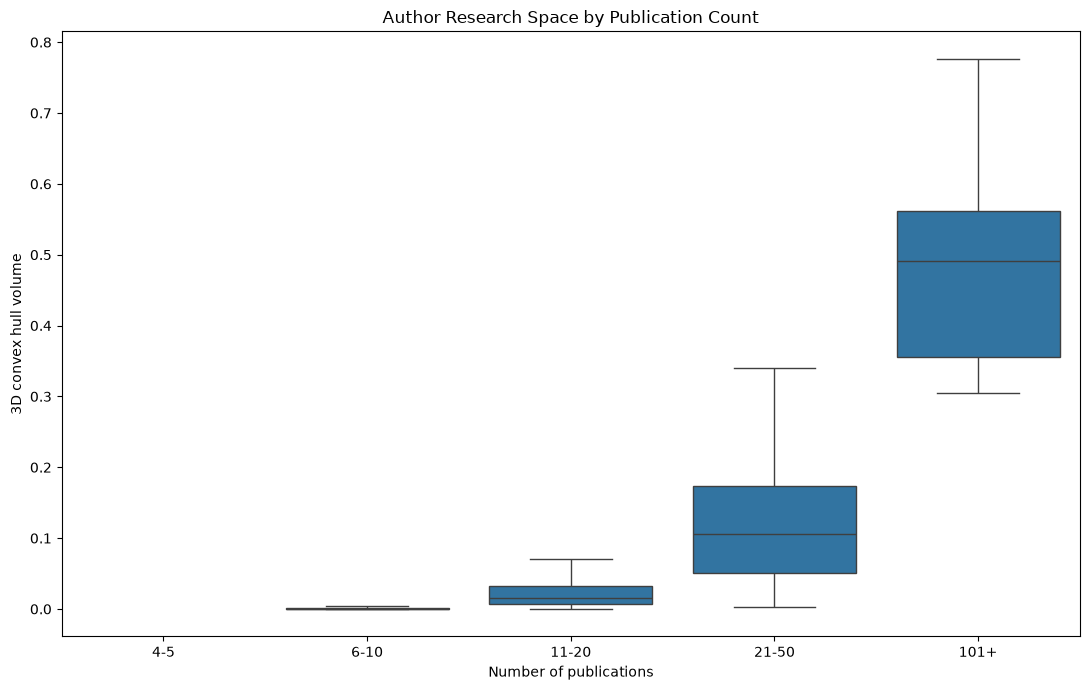

In [99]:
plt.figure(figsize=(11, 7))

sns.boxplot(
    data=authors_binned,
    x="publication_bin",
    y="hull_volume",
    showfliers=False
)

plt.xlabel("Number of publications")
plt.ylabel("3D convex hull volume")
plt.title("Author Research Space by Publication Count")

plt.tight_layout()
plt.show()


In [100]:
def bootstrap_hull_ci(
    authors_binned: pd.DataFrame,
    volume_col: str = "hull_volume",
    bin_col: str = "publication_bin",
    n_bootstrap: int = 10000,
    confidence: float = 0.95,
    random_state: int = 42,
):
    """
    Calculates bootstrap confidence intervals for mean
    convex hull volume within each publication bin.

    Resamples authors with replacement.
    """

    rng = np.random.default_rng(random_state)

    alpha = 1 - confidence
    results = []

    for bin_name, group in authors_binned.groupby(
        bin_col, observed=False
    ):

        values = group[volume_col].dropna().to_numpy()
        n = len(values)

        if n == 0:
            continue

        # Observed statistics
        observed_mean = np.mean(values)
        observed_median = np.median(values)

        if n < 2:
            results.append({
                "publication_bin": bin_name,
                "n_authors": n,
                "mean_volume": observed_mean,
                "median_volume": observed_median,
                "ci_lower": np.nan,
                "ci_upper": np.nan,
            })
            continue

        # Bootstrap resampling
        bootstrap_means = np.empty(n_bootstrap)

        for i in range(n_bootstrap):
            sample = rng.choice(
                values,
                size=n,
                replace=True
            )

            bootstrap_means[i] = np.mean(sample)

        # Percentile confidence interval
        ci_lower, ci_upper = np.quantile(
            bootstrap_means,
            [alpha / 2, 1 - alpha / 2]
        )

        results.append({
            "publication_bin": bin_name,
            "n_authors": n,
            "mean_volume": observed_mean,
            "median_volume": observed_median,
            "std_volume": np.std(values, ddof=1),
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
        })

    return pd.DataFrame(results)


In [101]:
hull_ci = bootstrap_hull_ci(
    authors_binned,
    volume_col="hull_volume",
    n_bootstrap=10000,
    confidence=0.95
)

print(hull_ci)

  publication_bin  n_authors  mean_volume  median_volume  std_volume  \
0            6-10        707     0.002130       0.000483    0.004163   
1           11-20        330     0.024152       0.015495    0.025210   
2           21-50        104     0.124366       0.105639    0.092812   
3            101+          8     0.496811       0.491284    0.166479   

   ci_lower  ci_upper  
0  0.001836  0.002441  
1  0.021495  0.026921  
2  0.106785  0.143145  
3  0.395600  0.608630  


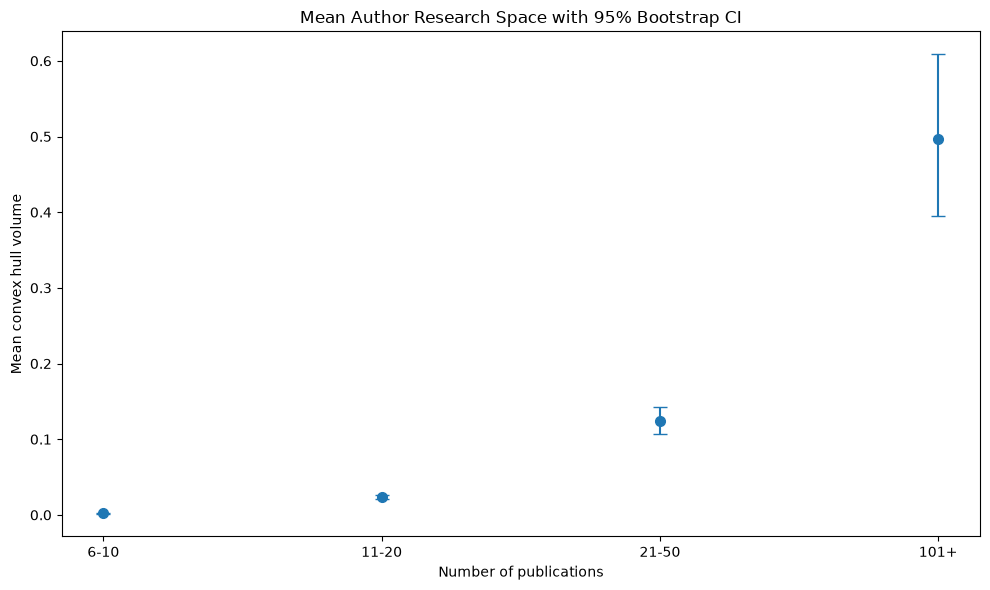

In [102]:
plot_data = hull_ci.dropna(subset=["ci_lower", "ci_upper"])

x = np.arange(len(plot_data))

means = plot_data["mean_volume"].values

lower_errors = means - plot_data["ci_lower"].values
upper_errors = plot_data["ci_upper"].values - means

plt.figure(figsize=(10, 6))

plt.errorbar(
    x,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5,
    markersize=7
)

plt.xticks(
    x,
    plot_data["publication_bin"].astype(str)
)

plt.xlabel("Number of publications")
plt.ylabel("Mean convex hull volume")
plt.title("Mean Author Research Space with 95% Bootstrap CI")

plt.tight_layout()
plt.show()


This function maps the calculated hulls to the 

In [103]:
def map_author_hulls_to_papers(
    df: pd.DataFrame,
    author_hulls: pd.DataFrame,
    author_col: str = "last_author",
):
    """
    Maps each author's convex hull statistics to all papers
    for which they are the last author.

    Returns the original DataFrame with author-level convex
    hull statistics appended to each paper.
    """

    # Select author-level convex hull statistics
    hull_cols = [
        "author",
        "n_papers",
        "n_unique_points",
        "hull_vertices",
        "hull_volume",
        "hull_area",
        "status",
    ]

    hull_data = author_hulls[hull_cols].copy()

    # Merge author hull statistics onto original papers
    df_mapped = df.merge(
        hull_data,
        left_on=author_col,
        right_on="author",
        how="left"
    )

    # Remove redundant author column
    df_mapped = df_mapped.drop(columns=["author"])

    return df_mapped

In [104]:
df_with_hulls = map_author_hulls_to_papers(
    df=papers_pca,
    author_hulls=author_hulls
)

In [105]:
df_with_hulls.head()

,paper_idx,year,id,title,abstract,authors,author_ids,decision,scores,keywords,...,pca_2,pca_3,pca_4,pca_5,n_papers,n_unique_points,hull_vertices,hull_volume,hull_area,status
0,5637,2021,--GJkm7nt0,Enhancing Visual Representations for Efficient...,"We propose ENVISE, an online distillation fra...","Shashanka Venkataramanan, Bruce W McIntosh, Ab...","~Shashanka_Venkataramanan1, ~Bruce_W_McIntosh1...",Reject,"[4, 5, 5, 4]",[],...,0.581444,-0.080378,-0.491848,0.057572,NaN,NaN,NaN,NaN,NaN,NaN
1,5638,2021,--gvHfE3Xf5,Meta-Learning of Structured Task Distributions...,"In recent years, meta-learning, in which a mod...","Sreejan Kumar, Ishita Dasgupta, Jonathan Cohen...","~Sreejan_Kumar1, ~Ishita_Dasgupta1, ~Jonathan_...",Accept (Poster),"[6, 6, 7, 7]","[meta-learning, human cognition, reinforcement...",...,-0.547058,-0.286767,-0.206954,0.101789,NaN,NaN,NaN,NaN,NaN,NaN
2,5639,2021,--rcOeCKRh,CROSS-SUPERVISED OBJECT DETECTION,After learning a new object category from imag...,"Zitian Chen, Zhiqiang Shen, Jiahui Yu, Erik Le...","~Zitian_Chen1, ~Zhiqiang_Shen1, ~Jiahui_Yu1, ~...",Reject,"[6, 4, 6, 6]","[object detection, weakly supervised, transfer...",...,0.535791,-0.354537,-0.668334,-0.251020,NaN,NaN,NaN,NaN,NaN,NaN
3,5640,2021,-2FCwDKRREu,Learning Invariant Representations for Reinfor...,We study how representation learning can accel...,"Amy Zhang, Rowan Thomas McAllister, Roberto Ca...","~Amy_Zhang1, ~Rowan_Thomas_McAllister1, ~Rober...",Accept (Oral),"[7, 7, 9]","[rich observations, bisimulation metrics, repr...",...,-0.240694,-0.839848,-0.261794,-0.205804,67.0,67.0,51.0,0.30524,3.407873,success
4,5641,2021,-5VpoDCExrU,Log representation as an interface for log pro...,"Log files are files that record events, messag...","Mohammad Amin Sadeghi, Shameem Parambath, Ji L...","~Mohammad_Amin_Sadeghi3, spparambath@hbku.edu....",Reject,"[7, 4, 5, 3]","[vector embedding, logs, search, causal analys...",...,0.175122,0.048539,0.512127,0.363295,NaN,NaN,NaN,NaN,NaN,NaN


If you want to export this for further analysis, uncomment the code below and set the number of dims X you used

In [106]:
# df_with_hulls.to_parquet(f"master_convex_{X}.parquet", index=False) 